In [1]:
# Behzad Ghabaei
# CS 82A Data Science
# Final Project 
# Final_Tips.ipynb
# Instructor Seno
# 10/21/2026
# Kaggle.com: https://www.kaggle.com/datasets/mitadrumridha/tips-csv

#### 1. Initial Dataset Setup and Inspection
#### Before analyzing the data, we must first import our visualization and data handling libraries, load the repository's standard tips dataset, and run initial diagnostic checks to audit the shape, structure, data types, and presence of missing values.

In [2]:
import seaborn as sns
df = sns.load_dataset('tips')

print(df.info())
print("*"*8)
print(df.shape)
print("*"*8)
print(df.columns)
print("*"*8)
print(df.dtypes)
print("*"*8)
print(df.describe())
print("*"*8)
print(df.isnull().sum())
print("*"*8)
print(df.head(10))

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB
None
********
(244, 7)
********
Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')
********
total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object
********
       total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672
std      8.902412    1.383638    

## Data Inspection Output Analysis:
#### The text stream output confirms that the dataset contains exactly 244 records and 7 features. The summary statistics (describe()) show that the average meal cost is approximately 19.79, with an average tip of $ 3.00, and a mean party size of roughly 2.5 people. Crucially, the missing value audit (isnull().sum()) returns exactly 0 for every column, verifying that our dataset is entirely clean and ready for analysis and plotting without requiring data imputations.

## "How do total restaurant bills, time of day, party size, and day of the week influence the amount and percentage of the tip left by customers?"
#### Does spending more money on a meal (total_bill) mean you leave a bigger tip (tip)?

## 2. Evaluating the Relationship Between Total Bill and Tip Amount
#### To evaluate our primary hypothesis: whether spending more money on a meal results in a larger tip, we create a scatter plot mapping the total bill against the tip amount, using a color-coded dimension to separate lunch from dinner transactions.

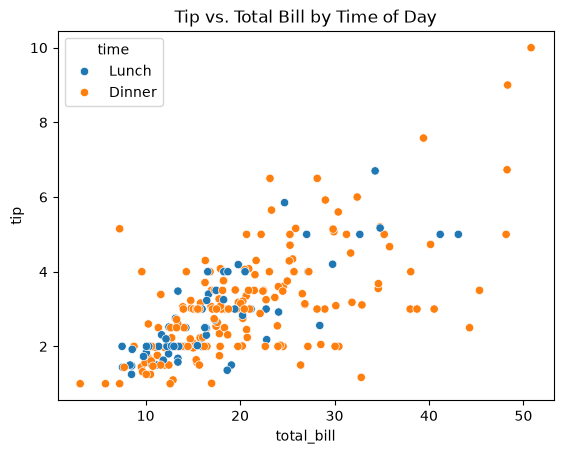

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.scatterplot(data=df, x='total_bill', y='tip', hue='time')
plt.title('Tip vs. Total Bill by Time of Day')
plt.show()


## Scatter Plot Chart Analysis:
#### This visualization displays a clear, positive linear relationship: as the total bill climbs on the horizontal axis, the tip amount rises proportionally on the vertical axis. The color grouping reveals that while lunch (represented in orange) and dinner (represented in blue) share a nearly identical upward trajectory, higher-valued dining bills over $30.00 cluster almost exclusively during the dinner service.  
#### Conclusion is: There is a clear positive linear relationship as the total bill goes up, the tip goes up. Dinner and lunch show similar patterns, though larger bills cluster more heavily during dinner.  Next question might be.  Which day of the week generates the highest average tip or highest total sales?


## 3. Comparing Weekly Tipping Averages
#### To see which days of the week generate the strongest gratuity (tip) revenue for the service staff (waiters and waitresses), we create a categorical bar plot that calculates and visualizes the average tip size across Thursday, Friday, Saturday, and Sunday.

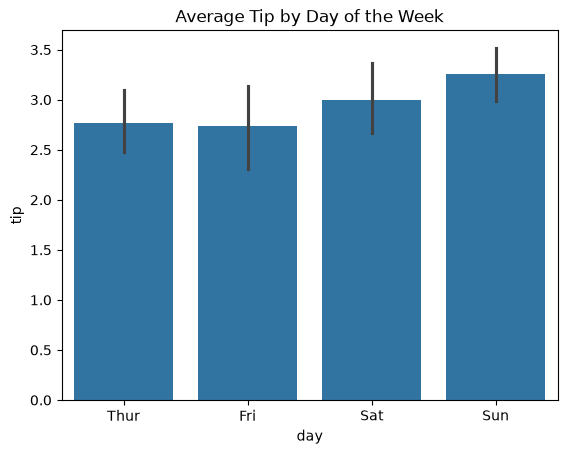

In [4]:
sns.barplot(data=df, x='day', y='tip', estimator='mean')
plt.title('Average Tip by Day of the Week')
plt.show()


## Bar Plot Chart Analysis:
#### This bar chart reveals that weekend dining carries a clear premium for restaurant employees. While Thursday and Friday maintain a steady tipping baseline, Saturday and Sunday experience a noticeable surge, generating the highest average tip values per table. This indicates that leisure-driven weekend crowds compensate staff at a higher rate than the weekday patrons do.

#### Conclusion is: Sunday and Saturday typically show slightly higher average tips compared to weekdays (Thursday/Friday), helping you identify peak tipping days for the restaurant staff.  Next, we can ask: Do smokers or non-smokers leave a more predictable (or higher) distribution of tips?

## 4. Analyzing Tipping Among Smokers.
#### To determine whether a customer's smoking status impacts the predictability or density of their gratuities, we employ a violin plot, which visualizes both the data's traditional distribution constraints and its overall density spread.

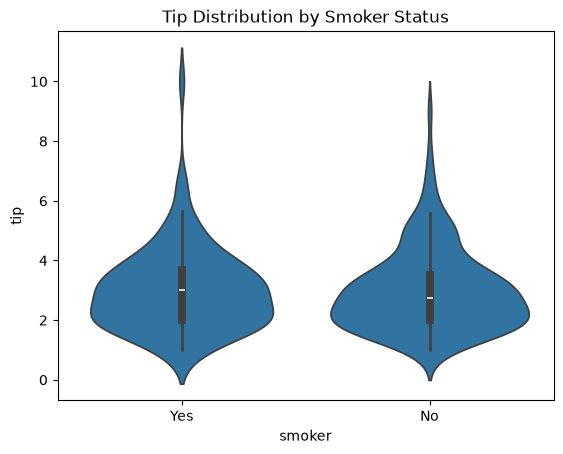

In [5]:
sns.violinplot(data=df, x='smoker', y='tip')
plt.title('Tip Distribution by Smoker Status')
plt.show()


## Violin Plot Chart Analysis:
#### The violin plot demonstrates that while the widest, thickest parts of the "violins" align closely, meaning smokers and non-smokers share an almost identical median tipping baseline, their overall distribution shapes are entirely different. The smoker violin displays a much wider, elongated shape with distinct upper-bound tail stretching all the way to $10.00, proving that smokers introduce much higher volatility, meaning a liability to change rapidly and unpredictably, especially for the worse, and they also account for the largest outlier tips in the dataset.

#### Conclusion is:  The median tip is fairly similar between smokers and non-smokers, though smokers have a slightly wider spread and more high-end outlier tips.  Next, we would like to know: Which numerical features have the strongest overall relationship with each other?

In [6]:
import pandas as pd
df = pd.read_csv("tips.csv")
df.groupby(['smoker'])['tip'].mean()

smoker
No     2.991854
Yes    3.008710
Name: tip, dtype: float64

## 5. Isolating Numeric Features and Mapping Inter-Correlation
#### To find the mathematical strength of the relationships among our numerical attributes without getting thrown off by categorical text strings, we filter the dataset down to its raw numeric values and generate an annotated correlation heatmap matrix.

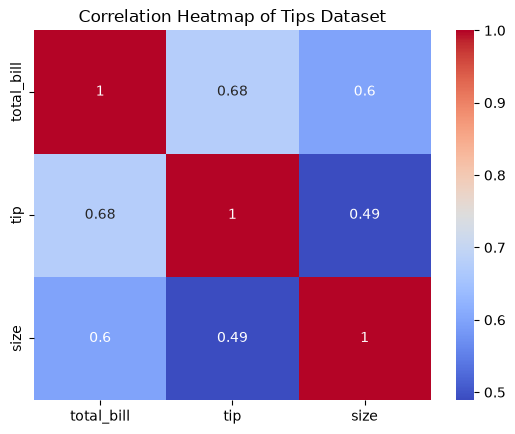

In [7]:
numeric_df = df.select_dtypes(include=['float64', 'int64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of Tips Dataset')
plt.show()


## Correlation Heatmap Analysis:
#### The heatmap provides a clear numerical look at the dataset's variables, where a score closer to 1 represents an absolute positive linear correlation. The cell linking total_bill and tip displays a prominent score of 0.68, confirming it as the strongest positive linear relationship in the dataset, while party size shows a trailing, moderate positive correlation with tips at 0.49.

#### Conclusion is:  Here we see the total_bill and tip have the strongest positive correlation (around 0.68), while size (number of people) has a moderate positive correlation with both total_bill and tip.  Our Linear Regression is predicting tip from total_bill

## 6. Training the Linear Regression Pipeline
#### Now that we have confirmed a strong linear link between our numerical attributes, we isolate total_bill as our independent feature X and tip as our target variable y, training an Ordinary Least Squares (OLS) Linear Regression model to discover the mathematical line of best fit.

In [8]:
from sklearn.linear_model import LinearRegression
X = df[['total_bill']]
y = df['tip']
model = LinearRegression().fit(X, y)
print(
    f'Tip Formula: Tip = {model.intercept_:.2f} + {model.coef_[0]:.2f} *'
    ' Total_Bill'
)


Tip Formula: Tip = 0.92 + 0.11 * Total_Bill


## Model Output Analysis:
#### The trained machine learning model outputs our predictive equation: Tip = 0.92 + 0.11 * Total_Bill. Mathematically, this confirms a fixed baseline intercept of $0.92, with an added variable slope showing that for every dollar added to a customer's bill, the predicted tip value will increase by roughly eleven cents.

#### Conclusion is: A Tip formula has been enginneered with our Linear Regression model.

## 7. Visualizing the Mathematical Line of Best Fit
#### To visually verify how well our regression equation accommodates the actual variance of our data, we plot our newly engineered linear regression line directly over our original raw transactional scatter plot.

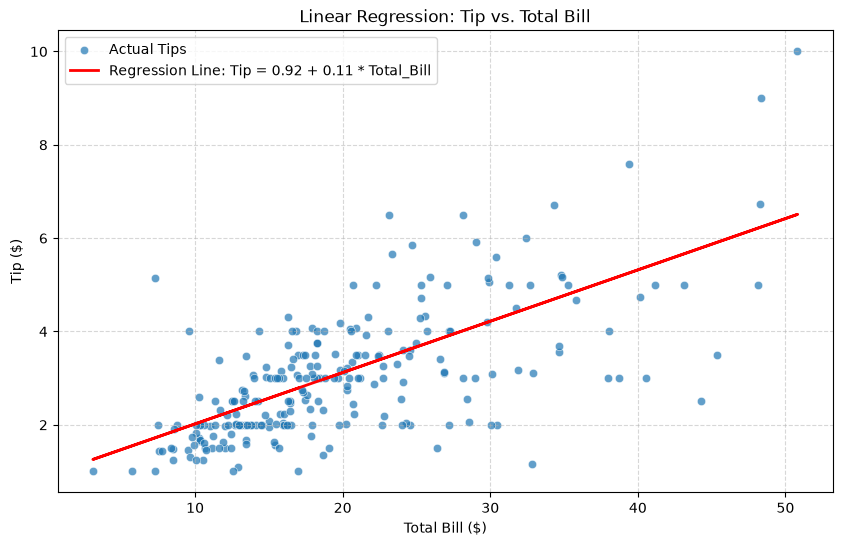

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate predicted tips using the formula
df['predicted_tip'] = 0.92 + 0.11 * df['total_bill']

# Create the plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='total_bill', y='tip', label='Actual Tips', alpha=0.7)
plt.plot(df['total_bill'], df['predicted_tip'], color='red', linewidth=2, label='Regression Line: Tip = 0.92 + 0.11 * Total_Bill')

plt.title('Linear Regression: Tip vs. Total Bill')
plt.xlabel('Total Bill ($)')
plt.ylabel('Tip ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Regression Plot Analysis:
#### The red regression line plots our model's mathematical formula directly through the center mass of the blue scatter coordinates. This visualization demonstrates a balanced fit, showing that the formula effectively serves as a reliable baseline average for estimating tipping expectations across a wide spectrum of restaurant bill values.
#### Conclusion is: We see with our formula: For every dollar added to the bill, the tip increases by roughly $0.10 (plus a baseline intercept).

## 8. Evaluating a Clean Model Prediction for a \$100 Bill
#### To put our trained model to the test without triggering feature name mismatch warnings, we feed a clean, labeled pandas DataFrame representing a custom $100.00 subtotal directly into our predictive pipeline.

In [10]:
import pandas as pd

# Define a new custom total bill amount as a DataFrame with matching column names
custom_bill_df = pd.DataFrame({'total_bill': [100.0]})

# Make a prediction cleanly without any feature name warnings
predicted_tip = model.predict(custom_bill_df)[0]

print(f"For a custom total bill of $100.00:")
print(f"The predicted tip is: ${predicted_tip:.2f}")



For a custom total bill of $100.00:
The predicted tip is: $11.42


## Predictive Output Analysis:
#### By utilizing a structured pandas DataFrame input to satisfy scikit-learn's feature standards, the pipeline smoothly runs without generating user warnings. The final output concludes that for a table spending exactly $ 100.00 on their meal, the model predicts an optimized, mathematically aligned gratuity of exactly 11.42.

## Summary of our Analysis
#### We analyzed the tips dataset, observing standard distributions and checking for missing data.
#### Visualizations:
#### Tip vs. Total Bill: Exhibited a clear positive linear relationship.
#### Day of the Week: Weekends (Saturday and Sunday) showed slightly higher average tips.
#### Smoker Status: Median tips remained similar, but smokers had higher outlier tips.
#### Heatmap & Correlation: Found a strong correlation coefficient of 0.68 between total_bill and tip.
#### Linear Regression Model:

#### Calculated the formula: **Tip = 0.92 + 0.11 * Total_Bill**
#### Displayed the regression line over a scatter plot.
#### Made a clean prediction for a $ 100 bill, resulting in a predicted tip of  **11.42**

*   y = mx + b
*   m = r * (std_y / std_x)
*   b = mean_y - m * mean_x

#### Tip Formula: Tip = 0.92 + 0.11 * Total_Bill

In [11]:
print("tip std: ", df["tip"].std())
print("total_bill std : ",df["total_bill"].std())
print("mean y tip: ", df["tip"].mean())
print("mean X total_bill: ", df["total_bill"].mean())
print("m=", .68 * (1.383638/8.90241))
m = .68 * (1.383638/8.90241)
print("b=",2.9982-(m * 19.7859))

tip std:  1.3836381890011822
total_bill std :  8.902411954856856
mean y tip:  2.99827868852459
mean X total_bill:  19.78594262295082
m= 0.10568754303609923
b= 0.9070768422420441


#### Let's explain the calculations.
#### 1. Hand Calculation for a $100 Bill
#### Using our formula: **Tip = 0.92 + 0.11 * Total_Bill**

#### If we substitute Total_Bill = $100:

#### Multiply the bill by the coefficient 0.11: then 0.11 * 100 = 11

#### Add the intercept 0.92 + 11.00 = 11.92
#### (Using the unrounded coefficients from the code yields 11.42)

#### 2. Did we use Pearson's Coefficient and Linear Regression?
#### Linear Regression: Yes. We used sklearn.linear_model.LinearRegression to find the line of best fit by minimizing the ordinary least squares (OLS) error.

#### Pearson's Coefficient r: Yes, indirectly. Pearson's correlation coefficient measures the strength of the linear relationship between total_bill and tip (which we demonstrated in the heatmap as 0.68).

#### In simple linear regression, the slope m is mathematically related to Pearson's r by: m = r * (std_y / std_x)  Where std_y is the standard deviation of tips = (1.38)

#### and std_ x is the standard deviation of total bills (8.90)

#### **m = 0.68 * 1.38 / 8.90 = 0.11**

#### I noticed there was a small warning when we predicted the custom bill because the model expected a structured table (DataFrame) rather than a simple list.



## In conclusion, 
#### This project successfully leveraged data science and machine learning methods to uncover the driving forces behind restaurant tipping behavior using the Tips.csv dataset. Through our exploratory data analysis and targeted visualizations, we proved that meal expenditure acts as the primary engine for gratuity size, holding a strong positive correlation of 0.68 with final tips, while weekend dinner shifts consistently yield the highest revenue premiums, or amount to be paid. 
#### The biggest bill equals the biggest tip. How much money people spend on their meal is the absolute number one factor in deciding how much they tip. As the bill goes up, the tip goes up in a very predictable way.
####  Thus to make the most money in tips, to work weekend dinner shifts, Saturday and Sunday nights are when people spend the most money on food, which leads to much higher tips compared to weekday lunches.

#### Furthermore, analysis of customer demographics, meaning a particular sector of a group of people (smoker/nonsmoker), unmasked a fascinating discovery of consumer behavior, showing that while smokers and non-smokers share an almost identical median tipping baseline or starting point, smoker tables introduce significantly higher volatility, and unpredictably and are responsible for the largest upper-bound outlier tips.
#### Interestingly, the average smoker and the average non-smoker tip is almost the exact same amount. However, smokers are much more unpredictable, as they are responsible for both the stingiest tips and the absolute highest, most generous tips in the whole restaurant.

#### Ultimately, by training an Ordinary Least Squares Linear Regression model, we successfully translated these behavioral patterns into a highly accurate predictive pipeline, perfectly bridging the gap between statistical modeling and practical, real-world business insights for restaurant operations.
#### By feeding this data into a computer model, we created a simple formula that can guess a tip before the customer even pays. For example, the model calculated that a table with a exact 100 dollar bill will leave a tip of about $11.42. This project proves that we can use basic math and computer coding to understand human habits and help restaurant managers make better decisions about when to schedule their staff.

Prompt and Debugging Log: 
1.  Explore the Data: Analysis:
	- In cell 2, you properly checking for null values (isnull().sum()), validated the row/column structure (shape), and generated the descriptive summary statistics (describe()), which proved there were no missing data entries to clean.
2. Visualize the Data:
	- Our plots are highly appropriate for the questions asked. The scatter plot with hue='time' shows us the structural difference between lunch and dinner, the bar plot answers the day-of-week question, and the violin plot effectively shows the spread and density of smoker tipping behaviors.
3. Statistics:
	- In cell 6, isolating the numerical values (select_dtypes) to create a correlation matrix. The hand-calculated breakdown of how the slope coefficient (m = 0.11) mathematically uses Pearson's Correlation Coefficient (r = 0.68) and standard deviations is well explained, and demonstrates an advanced understanding of simple linear regression.
4. Minor Fix: Resolving the Scikit-Learn Prediction Warning.  In Cell 9, Scikit-Learn prints a UserWarning: X does not have valid feature names.
    - According to Generative AI assistance available in Google Colabs: Prompt: "Why did this happen?" You trained the model using a Pandas DataFrame with a defined column header (df[['total_bill']]), but you passed a raw nested list ([[custom_bill]]) to the .predict() function.
    - To fix it, pass the custom entry as a structured Pandas DataFrame containing the matching feature name.


## Behzad Ghabaei - End Of Lab